# Autoencoder (AE) vs Variational Autoencoder (VAE)
## Image Reconstruction and Generation using MNIST

**Assignment objectives**
1. Prepare the MNIST image dataset.
2. Build and train an Autoencoder (AE).
3. Build and train a Variational Autoencoder (VAE).
4. Reconstruct test images with both models.
5. Generate new images and compare the models.
6. Evaluate reconstruction using Mean Squared Error (MSE).

**How to run:** Run all cells from top to bottom. Google Colab is recommended. The first run downloads MNIST and trains both models. Training time depends on your hardware.


## 1. Import libraries and set random seeds

TensorFlow/Keras is used to define and train the neural networks. NumPy is used for numerical operations, Matplotlib for visualizations, and scikit-learn for MSE.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.metrics import mean_squared_error

SEED = 42
tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: []


## 2. Load and preprocess the MNIST dataset

MNIST contains 28 × 28 grayscale images of handwritten digits. Pixel values are normalized to the range [0, 1], which works well with a sigmoid output layer. Labels are not needed because the models learn to reconstruct each input image.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28 × 28 image into a 784-element vector.
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 784)
Test images: (10000, 784)
Pixel range: 0.0 to 1.0


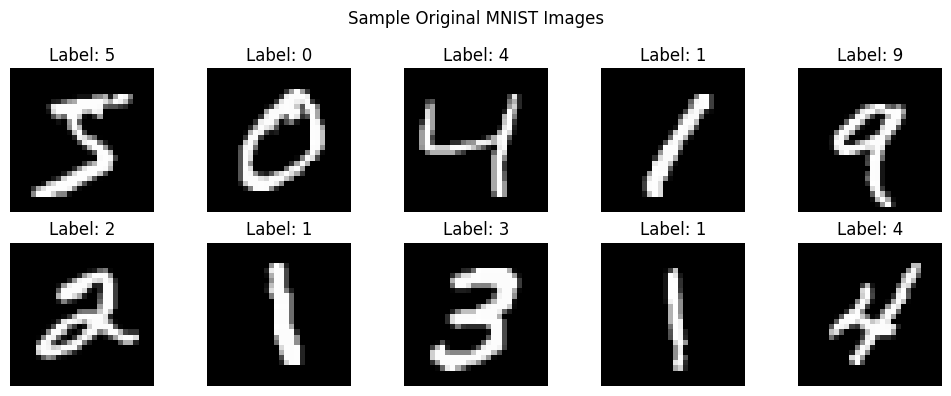

In [3]:
# Display a sample of original images
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample Original MNIST Images")
plt.tight_layout()
plt.show()


## 3. Build the Autoencoder (AE)

The encoder maps an image from 784 pixels to a 32-dimensional latent vector. The decoder maps that vector back to 784 pixel values. Binary cross-entropy is used as the reconstruction loss.

In [4]:
latent_dim = 32

# Encoder
ae_input = layers.Input(shape=(784,), name="ae_input")
x = layers.Dense(256, activation="relu")(ae_input)
x = layers.Dense(128, activation="relu")(x)
ae_latent = layers.Dense(latent_dim, activation="relu", name="ae_latent")(x)
ae_encoder = Model(ae_input, ae_latent, name="AE_Encoder")

# Decoder
ae_decoder_input = layers.Input(shape=(latent_dim,), name="ae_decoder_input")
x = layers.Dense(128, activation="relu")(ae_decoder_input)
x = layers.Dense(256, activation="relu")(x)
ae_decoded = layers.Dense(784, activation="sigmoid", name="ae_reconstruction")(x)
ae_decoder = Model(ae_decoder_input, ae_decoded, name="AE_Decoder")

# Complete Autoencoder
ae_output = ae_decoder(ae_encoder(ae_input))
autoencoder = Model(ae_input, ae_output, name="Autoencoder")

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

autoencoder.summary()


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Encoder (Functional)         │ (None, 32)             │       237,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Decoder (Functional)         │ (None, 784)            │       238,736 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the Autoencoder

The input and target are the same image (`x_train`). The model learns to reconstruct its input without using digit labels.

In [5]:
EPOCHS = 15
BATCH_SIZE = 256

ae_history = autoencoder.fit(
    x_train, x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)


Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - loss: 0.2186 - val_loss: 0.1445
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.1299 - val_loss: 0.1174
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.1142 - val_loss: 0.1087
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.1069 - val_loss: 0.1033
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - loss: 0.1013 - val_loss: 0.0984
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0975 - val_loss: 0.0951
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0949 - val_loss: 0.0931
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 0.0929 - val_loss: 0.0921
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - loss: 0.0914 - val_loss: 0.0898
Epoch 10/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0899 - val_loss: 0.0887
Epoch 11/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0887 - val_loss: 0.0875
Epoch 12/15
235/235 ━━━━━━━━━━━━━━━━━━━

## 5. Build the Variational Autoencoder (VAE)

Unlike the AE, the VAE encoder predicts a mean vector and a log-variance vector. The sampling layer uses the reparameterization trick: z = mean + exp(0.5 × log_variance) × epsilon, where epsilon is sampled from a standard normal distribution.

In [6]:
class Sampling(layers.Layer):
    """Sample a latent vector using the reparameterization trick."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


vae_input = layers.Input(shape=(784,), name="vae_input")
x = layers.Dense(256, activation="relu")(vae_input)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z_sample = Sampling(name="z_sampling")([z_mean, z_log_var])

vae_encoder = Model(
    vae_input,
    [z_mean, z_log_var, z_sample],
    name="VAE_Encoder"
)

vae_decoder_input = layers.Input(shape=(latent_dim,), name="vae_decoder_input")
x = layers.Dense(128, activation="relu")(vae_decoder_input)
x = layers.Dense(256, activation="relu")(x)
vae_decoded = layers.Dense(784, activation="sigmoid", name="vae_reconstruction")(x)

vae_decoder = Model(
    vae_decoder_input,
    vae_decoded,
    name="VAE_Decoder"
)

vae_encoder.summary()
vae_decoder.summary()


Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_input           │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │    200,960 │ vae_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │     32,896 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_sampling          │ (None, 32)        │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 242,112 (945.75 KB)

 Trainable params: 242,112 (945.75 KB)

 Non-trainable params: 0 (0.00 B)

Model: "VAE_Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_decoder_input (InputLayer)  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vae_reconstruction (Dense)      │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,736 (932.56 KB)

 Trainable params: 238,736 (932.56 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Define the VAE loss and training loop

The VAE optimizes two terms:

- **Reconstruction loss:** binary cross-entropy between original and reconstructed pixels.
- **KL divergence:** encourages the approximate latent distribution to stay close to a standard normal distribution.

The total loss is the sum of reconstruction loss and KL divergence. Both are summed over pixels/latent dimensions per image and then averaged across the batch.

In [7]:
class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        # Keras may pass the input as a tuple.
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            # Sum pixel losses per image, then average over the batch.
            per_pixel_bce = tf.keras.backend.binary_crossentropy(data, reconstruction)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(per_pixel_bce, axis=1)
            )

            # KL(q(z|x) || N(0, I))
            kl_per_image = -0.5 * tf.reduce_sum(
                1.0 + log_var - tf.square(mean) - tf.exp(log_var),
                axis=1
            )
            kl_loss = tf.reduce_mean(kl_per_image)

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def call(self, inputs, training=False):
        mean, log_var, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)


vae = VAE(vae_encoder, vae_decoder, name="VAE")
vae.compile(optimizer=tf.keras.optimizers.Adam())
print("VAE compiled successfully.")


VAE compiled successfully.


## 7. Train the VAE

This custom training loop tracks total loss, reconstruction loss, and KL divergence. Validation is not run through `fit` because this custom model defines only a training step; we will evaluate reconstruction on the held-out test set below.

In [8]:
vae_history = vae.fit(
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)


Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - kl_loss: 7.7710 - loss: 200.1613 - reconstruction_loss: 192.3903
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - kl_loss: 16.1495 - loss: 145.6187 - reconstruction_loss: 129.4692
Epoch 3/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - kl_loss: 18.7114 - loss: 131.0072 - reconstruction_loss: 112.2957
Epoch 4/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - kl_loss: 19.6474 - loss: 123.7739 - reconstruction_loss: 104.1265
Epoch 5/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - kl_loss: 20.3693 - loss: 119.1184 - reconstruction_loss: 98.7491 
Epoch 6/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - kl_loss: 21.0973 - loss: 116.0266 - reconstruction_loss: 94.9293
Epoch 7/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - kl_loss: 21.5449 - loss: 113.9345 - reconstruction_loss: 92.3896
Epoch 8/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - kl_loss: 21.8352 - loss: 112.3410 - reconstruction_loss: 90.5058
Epoch 9/15
235/235 ━━━━━━━━━━━━━━━━━

## 8. Reconstruct test images with both models

The same test images are passed to both models. For the VAE, the encoder's mean is used for a stable, deterministic reconstruction comparison. The sampled latent vector is still used during training and generation.

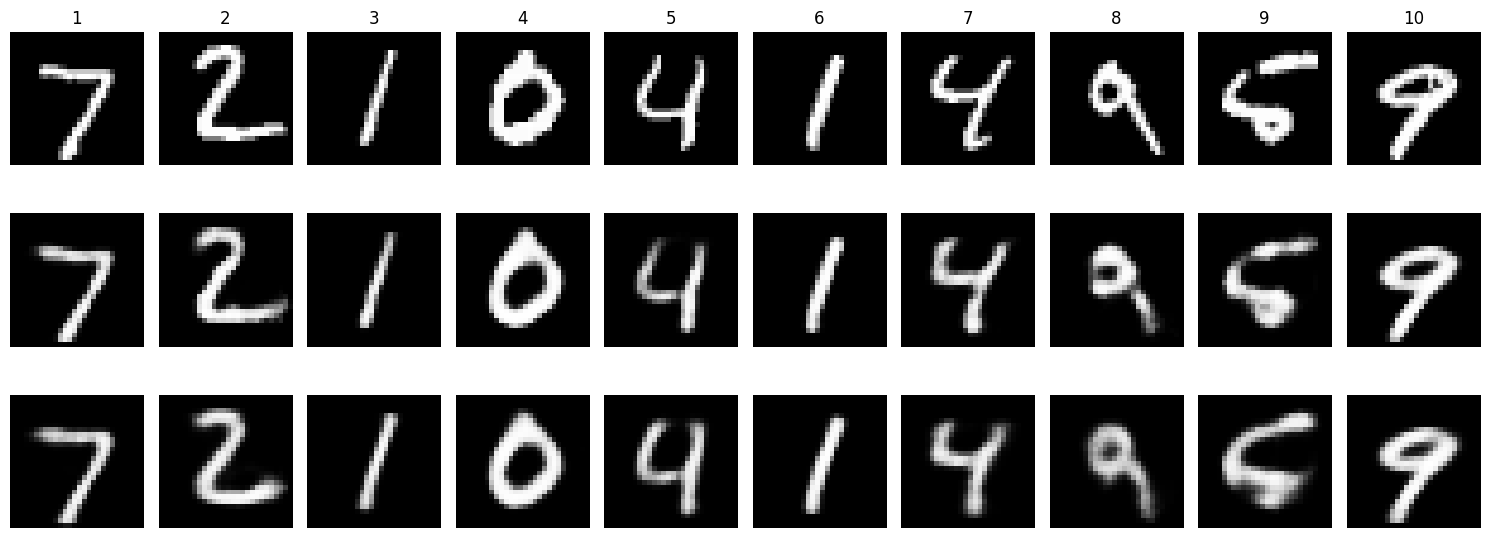

In [9]:
N_IMAGES = 10
original_images = x_test[:N_IMAGES]

ae_reconstructed = autoencoder.predict(original_images, verbose=0)

vae_mean, vae_log_var, vae_z = vae_encoder.predict(original_images, verbose=0)
# Use the mean for deterministic reconstruction comparisons.
vae_reconstructed = vae_decoder.predict(vae_mean, verbose=0)

def plot_image_rows(image_groups, titles, n_images=10):
    fig, axes = plt.subplots(len(image_groups), n_images, figsize=(1.5*n_images, 2.0*len(image_groups)))
    if len(image_groups) == 1:
        axes = np.expand_dims(axes, axis=0)
    for row, (images, title) in enumerate(zip(image_groups, titles)):
        for col in range(n_images):
            axes[row, col].imshow(images[col].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            axes[row, col].axis("off")
            if row == 0:
                axes[row, col].set_title(str(col + 1))
        axes[row, 0].set_ylabel(title, rotation=90, size="large", labelpad=12)
    plt.tight_layout()
    plt.show()

plot_image_rows(
    [original_images, ae_reconstructed, vae_reconstructed],
    ["Original", "AE reconstruction", "VAE reconstruction"],
    n_images=N_IMAGES
)


## 9. Generate new images

**AE:** a standard AE does not enforce a known distribution in latent space, so arbitrary random sampling is not guaranteed to work. We demonstrate interpolation between two encoded test images.

**VAE:** sample latent vectors from N(0, I) and pass them through the decoder to generate new digit-like images.

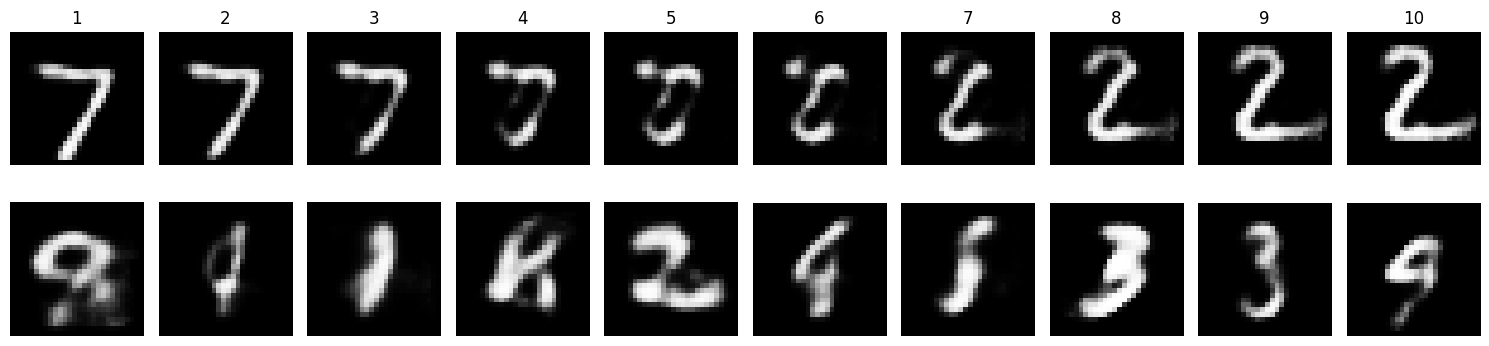

In [10]:
# Autoencoder: interpolate between two encoded test images.
z1 = ae_encoder.predict(x_test[0:1], verbose=0)[0]
z2 = ae_encoder.predict(x_test[1:2], verbose=0)[0]

alphas = np.linspace(0.0, 1.0, 10)
ae_generated = np.array([
    ae_decoder.predict(((1.0 - alpha) * z1 + alpha * z2)[None, :], verbose=0)[0]
    for alpha in alphas
])

# VAE: sample from the standard normal prior.
random_latent = rng.normal(size=(10, latent_dim)).astype("float32")
vae_generated = vae_decoder.predict(random_latent, verbose=0)

plot_image_rows(
    [ae_generated, vae_generated],
    ["AE interpolation", "VAE random samples"],
    n_images=10
)


## 10. Quantitative reconstruction comparison

Mean Squared Error (MSE) compares original and reconstructed pixel values. Lower MSE indicates smaller average squared pixel error, but it does not fully capture perceptual image quality.

The VAE reconstruction here uses the latent mean for deterministic output. The AE and VAE training losses should **not** be compared directly because their objective functions differ.

In [11]:
ae_mse = mean_squared_error(
    original_images.reshape(-1),
    ae_reconstructed.reshape(-1)
)
vae_mse = mean_squared_error(
    original_images.reshape(-1),
    vae_reconstructed.reshape(-1)
)

print(f"AE reconstruction MSE:  {ae_mse:.6f}")
print(f"VAE reconstruction MSE: {vae_mse:.6f}")

if ae_mse < vae_mse:
    print("On this test subset, AE has lower pixel-wise reconstruction error.")
elif vae_mse < ae_mse:
    print("On this test subset, VAE has lower pixel-wise reconstruction error.")
else:
    print("Both models have the same MSE on this test subset.")


AE reconstruction MSE:  0.007904
VAE reconstruction MSE: 0.010930
On this test subset, AE has lower pixel-wise reconstruction error.


## 11. Plot training losses

The AE plot shows binary cross-entropy. The VAE plot shows total VAE loss, reconstruction loss, and KL divergence. Because the AE and VAE objectives differ, their total training losses are not directly comparable.

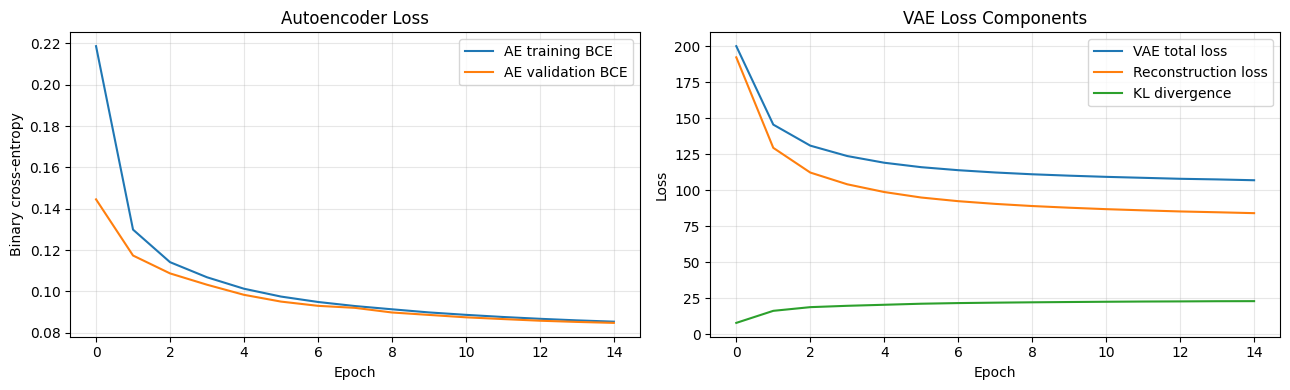

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(ae_history.history["loss"], label="AE training BCE")
axes[0].plot(ae_history.history["val_loss"], label="AE validation BCE")
axes[0].set_title("Autoencoder Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(vae_history.history["loss"], label="VAE total loss")
axes[1].plot(vae_history.history["reconstruction_loss"], label="Reconstruction loss")
axes[1].plot(vae_history.history["kl_loss"], label="KL divergence")
axes[1].set_title("VAE Loss Components")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 12. Results table and model comparison

The table below is populated with the MSE values measured by your notebook. Review the generated images as well; MSE alone cannot determine which generated images look most realistic.

In [13]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric / Feature": [
        "Test reconstruction MSE (lower is better)",
        "Latent representation",
        "Latent distribution regularization",
        "Generation method",
        "Typical strength",
        "Typical limitation"
    ],
    "Autoencoder (AE)": [
        f"{ae_mse:.6f}",
        "One fixed latent vector",
        "No explicit prior regularization",
        "Interpolate between encoded images",
        "Often prioritizes reconstruction fidelity",
        "Random latent samples may decode poorly"
    ],
    "Variational Autoencoder (VAE)": [
        f"{vae_mse:.6f}",
        "Mean and log variance; sampled latent vector",
        "KL divergence toward N(0, I)",
        "Sample random vectors from N(0, I)",
        "Structured latent space for generation",
        "Reconstructions can look smoother or blurrier"
    ]
})

display(comparison)


,Metric / Feature,Autoencoder (AE),Variational Autoencoder (VAE)
0,Test reconstruction MSE (lower is better),0.007904,0.010930
1,Latent representation,One fixed latent vector,Mean and log variance; sampled latent vector
2,Latent distribution regularization,No explicit prior regularization,"KL divergence toward N(0, I)"
3,Generation method,Interpolate between encoded images,"Sample random vectors from N(0, I)"
4,Typical strength,Often prioritizes reconstruction fidelity,Structured latent space for generation
5,Typical limitation,Random latent samples may decode poorly,Reconstructions can look smoother or blurrier


## 13. Analysis and conclusion (edit to match your results)

**Reconstruction:** Compare the original, AE-reconstructed, and VAE-reconstructed rows. Note whether digit shapes, edges, and strokes are preserved. Report the actual MSE values from the preceding cell. A lower MSE means lower pixel-wise error on this test subset, not necessarily better perceived quality.

**Generation:** AE interpolation decodes points between two real encoded images; the AE latent space is not explicitly forced to follow a normal distribution. VAE samples come from a standard normal prior, which is encouraged by KL divergence during training. Assess the generated grids for recognizable digits, variety, and artifacts.

**Conclusion:** Both models learn compressed representations and reconstruct MNIST images. The AE optimizes reconstruction error directly, while the VAE balances reconstruction with latent-distribution regularization. This often makes the VAE more suitable for random generation, while the AE can preserve individual input details more closely. Actual performance depends on training, architecture, and hyperparameters.

### Key viva questions

1. **What is an Autoencoder?** A neural network that compresses an input into a latent representation and reconstructs the input.
2. **What is latent space?** A lower-dimensional representation containing learned features of the image.
3. **How is a VAE different?** It learns a latent distribution using mean and variance rather than only a fixed encoded vector.
4. **Why is KL divergence used?** It encourages the approximate latent distribution to remain close to a standard normal prior.
5. **What is the reparameterization trick?** It expresses sampling as `z = mean + standard_deviation * epsilon`, allowing gradients to flow through the mean and variance.
6. **Which model is better?** It depends on the goal: reconstruction fidelity or generation from a structured latent space.
